## Charger les images

In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('data/fashion-mnist_train.csv')

## Affichage de l'image 1

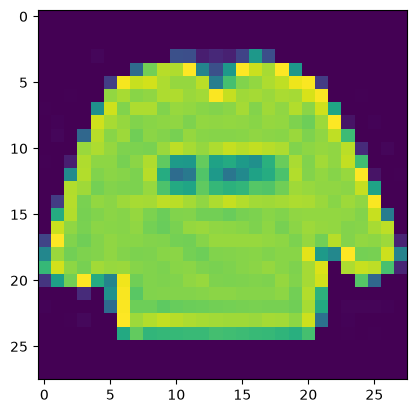

In [3]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage

In [4]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [5]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

## Préparation des données de tests

In [6]:
observations_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Une seule couche de convolution

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

#creation couche par couche
reseauNeurone1Convolution = Sequential()

#Ajout couche entrer
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#ajout couche comportant 32 filtres de taille 3x3
#fonction activation type ReLU
#image d'entrer de 28x28
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3,3),
                                     activation='relu'))

#def fonction de poolong avec une fenetre de 2x2
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2,2)))

#Ajout fonciton ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#transforme en 1 ligne
reseauNeurone1Convolution.add(Flatten())

#reseau neurone de 128n avec fonction ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#reseau neurone de 10n avec fonction softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax')) 

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8061 - loss: 0.5539 - val_accuracy: 0.8643 - val_loss: 0.3922
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8736 - loss: 0.3591 - val_accuracy: 0.8810 - val_loss: 0.3419
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8870 - loss: 0.3158 - val_accuracy: 0.8938 - val_loss: 0.3112
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8969 - loss: 0.2872 - val_accuracy: 0.8985 - val_loss: 0.2952
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9050 - loss: 0.2674 - val_accuracy: 0.9014 - val_loss: 0.2829
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9100 - loss: 0.2505 - val_accuracy: 0.9056 - val_loss: 0.2719
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9165 - loss: 0.2330 - val_accuracy: 0.9062 - val_loss: 0.2643
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9194 - loss: 0.2218 - val_accu

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.24482864141464233
Précision: 0.9129999876022339


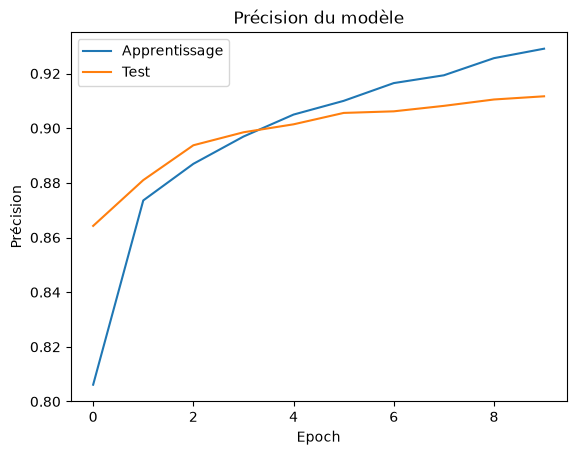

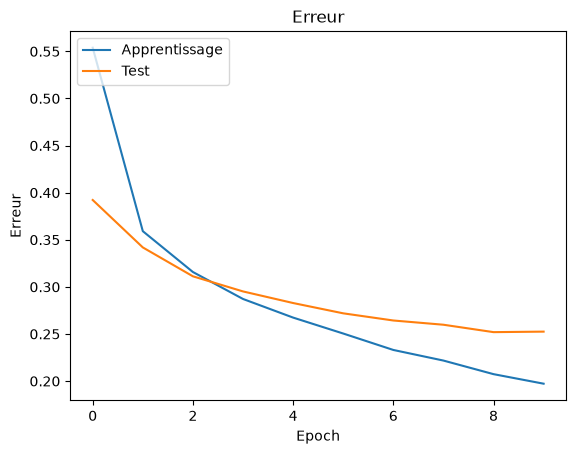

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## Augmentation du nombre de donnée

In [12]:
# from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

In [13]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.8262 - loss: 0.4611 - val_accuracy: 0.8499 - val_loss: 0.4068
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8398 - loss: 0.4202

c:\Users\gaman\2026\A26\cpp\ai\420-5G4-ML\analyse_image\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8398 - loss: 0.4202 - val_accuracy: 0.8470 - val_loss: 0.4140
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.8493 - loss: 0.4077 - val_accuracy: 0.8499 - val_loss: 0.3995
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8281 - loss: 0.4234 - val_accuracy: 0.8514 - val_loss: 0.4030
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.8571 - loss: 0.3842 - val_accuracy: 0.8508 - val_loss: 0.3889
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8594 - loss: 0.3943 - val_accuracy: 0.8551 - val_loss: 0.3846
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.8624 - loss: 0.3724 - val_accuracy: 0.8680 - val_loss: 0.3595
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8906 - loss: 0.3017 - val_accuracy: 0.8644 - val_loss: 0.3630
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.8675 - loss: 0.3600 - val_accuracy: 0.8681 - 

In [14]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


## Modele plus performant

In [15]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

c:\Users\gaman\2026\A26\cpp\ai\420-5G4-ML\analyse_image\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 152ms/step - accuracy: 0.7383 - loss: 0.7560 - val_accuracy: 0.1495 - val_loss: 2.7697
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - accuracy: 0.8442 - loss: 0.4379 - val_accuracy: 0.5421 - val_loss: 1.7071
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 25s 134ms/step - accuracy: 0.8689 - loss: 0.3661 - val_accuracy: 0.7433 - val_loss: 0.7879
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 140ms/step - accuracy: 0.8842 - loss: 0.3260 - val_accuracy: 0.8953 - val_loss: 0.2890
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 136ms/step - accuracy: 0.8925 - loss: 0.3019 - val_accuracy: 0.9027 - val_loss: 0.2708
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 25s 132ms/step - accuracy: 0.8980 - loss: 0.2841 - val_accuracy: 0.9078 - val_loss: 0.2504
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 25s 134ms/step - accuracy: 0.9042 - loss: 0.2690 - val_accuracy: 0.9090 - val_loss: 0.2575
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - accuracy: 0.9067 - loss: 0

In [17]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.25206270813941956
Précision: 0.9143999814987183


In [18]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 29s 150ms/step - accuracy: 0.8530 - loss: 0.4027 - val_accuracy: 0.8814 - val_loss: 0.3238
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8867 - loss: 0.3627 - val_accuracy: 0.8707 - val_loss: 0.3425
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 28s 151ms/step - accuracy: 0.8701 - loss: 0.3592 - val_accuracy: 0.8568 - val_loss: 0.3763
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8945 - loss: 0.3298 - val_accuracy: 0.8564 - val_loss: 0.3789
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 27s 144ms/step - accuracy: 0.8751 - loss: 0.3429 - val_accuracy: 0.8778 - val_loss: 0.3414
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8867 - loss: 0.2878 - val_accuracy: 0.8770 - val_loss: 0.3413
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 27s 142ms/step - accuracy: 0.8807 - loss: 0.3302 - val_accuracy: 0.8866 - val_loss: 0.2960
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8633 - loss: 0.3788 - val_

In [19]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele_performant.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele_performant.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
